# Member 1 — Classification Track, Part B (Adult / Census Income)

**Review 2 scope (Member 1):** two Part-B algorithms — **Random Forest** and **AdaBoost**.

- Same dataset, cleaning, engineered features, stratified 80:20 split (`random_state=42`) and train-only
  encoder/scaler as Review 1 Part A. The pipeline lives in `adult_prep.py` so every Part-B notebook scores on the
  exact same 9,035 test rows as Part A.
- Metrics (all mandatory): accuracy, weighted precision / recall / F1, confusion matrix, ROC-AUC. Macro F1 and
  balanced accuracy are added because the target is imbalanced (~75% `<=50K`).
- Each model: baseline fit -> hyperparameter tuning with `GridSearchCV` (stratified 5-fold, scored on weighted F1)
  -> improvement documented.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from pathlib import Path
from IPython.display import display

from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_validate
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, balanced_accuracy_score,
                             roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay, classification_report)

from adult_prep import prepare, RANDOM_STATE

np.random.seed(RANDOM_STATE)
sns.set_theme(style='whitegrid', palette='colorblind')
# joblib workers emit a harmless config-propagation warning on every parallel fit
warnings.filterwarnings('ignore', message='.*sklearn.utils.parallel.delayed.*')

RESULTS_DIR = Path('../results/classification')
MODELS_DIR = Path('../models/classification')
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

def save_fig(name):
    plt.tight_layout()
    plt.savefig(RESULTS_DIR / name, dpi=150, bbox_inches='tight')

## 1. Load the Review 1 preprocessed split

`prepare()` runs the Part A pipeline: pool the two UCI files, drop `?` rows and duplicates, `log1p` the capital
columns, add `net_capital` and `overtime`, drop `fnlwgt` and `education`, stratified 80:20 split, then fit the
one-hot encoder and `StandardScaler` on the **training set only**.

In [2]:
data = prepare('../data/raw/adult')
X_train, X_test = data['X_train'], data['X_test']
y_train, y_test = data['y_train'], data['y_test']
class_names = list(data['target_le'].classes_)

print('train:', X_train.shape, '| test:', X_test.shape)
print('share of >50K  train: %.3f | test: %.3f' % (y_train.mean(), y_test.mean()))

train: (36140, 89) | test: (9035, 89)
share of >50K  train: 0.248 | test: 0.248


**Check.** 36,140 training and 9,035 test rows with 89 features and the same ~24.8% `>50K` share in both — identical
to Review 1, so Part A and Part B numbers can go in one table.

In [3]:
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def score(model, X, y_true):
    """All required metrics for one fitted model on one data set."""
    pred = model.predict(X)
    proba = model.predict_proba(X)[:, 1]
    return {
        'accuracy': accuracy_score(y_true, pred),
        'precision_weighted': precision_score(y_true, pred, average='weighted', zero_division=0),
        'recall_weighted': recall_score(y_true, pred, average='weighted'),
        'f1_weighted': f1_score(y_true, pred, average='weighted'),
        'f1_macro': f1_score(y_true, pred, average='macro'),
        'balanced_accuracy': balanced_accuracy_score(y_true, pred),
        'roc_auc': roc_auc_score(y_true, proba),
    }

def tune(estimator, grid):
    """Stratified 5-fold grid search on the training set, ranked by weighted F1."""
    search = GridSearchCV(estimator, grid, scoring='f1_weighted', cv=CV, n_jobs=-1, return_train_score=True)
    search.fit(X_train, y_train)
    return search

results, models = {}, {}

## 2. Random Forest

An ensemble of decision trees, each grown on a bootstrap sample and a random subset of features per split;
averaging many decorrelated trees lowers the variance of a single deep tree (the Part A Decision Tree).

Starting values: `n_estimators=100`, `class_weight='balanced'` to counter the 75/25 imbalance (same choice as the
Part A tree), `min_samples_leaf=5` so leaves are not single people.

In [4]:
from sklearn.ensemble import RandomForestClassifier

rf_base = RandomForestClassifier(n_estimators=100, min_samples_leaf=5, class_weight='balanced',
                                 n_jobs=-1, random_state=RANDOM_STATE)
rf_base.fit(X_train, y_train)
results['Random Forest (base)'] = score(rf_base, X_test, y_test)
pd.Series(results['Random Forest (base)']).round(4)

accuracy              0.8220
precision_weighted    0.8593
recall_weighted       0.8220
f1_weighted           0.8310
f1_macro              0.7888
balanced_accuracy     0.8339
roc_auc               0.9170
dtype: float64

### 2.1 Tuning `n_estimators` (and tree depth)

The guideline asks to tune `n_estimators`. `max_depth` and `min_samples_leaf` are tuned with it because they control
how far each tree can overfit. Scoring is weighted F1 with stratified 5-fold CV on the training set only — the test
set is not touched until the best setting is chosen.

In [5]:
rf_grid = {
    'n_estimators': [100, 200, 400],
    'max_depth': [None, 20],
    'min_samples_leaf': [1, 5],
}
rf_search = tune(RandomForestClassifier(class_weight='balanced', n_jobs=-1, random_state=RANDOM_STATE), rf_grid)
print('best params:', rf_search.best_params_)
print('best CV weighted F1: %.4f' % rf_search.best_score_)

rf_cv = (pd.DataFrame(rf_search.cv_results_)
         [['param_n_estimators', 'param_max_depth', 'param_min_samples_leaf',
           'mean_train_score', 'mean_test_score', 'std_test_score']]
         .sort_values('mean_test_score', ascending=False).reset_index(drop=True))
display(rf_cv.round(4))

/opt/homebrew/Cellar/jupyterlab/4.6.2/libexec/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/opt/homebrew/Cellar/jupyterlab/4.6.2/libexec/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/opt/homebrew/Cellar/jupyterlab/4.6.2/libexec/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(


/opt/homebrew/Cellar/jupyterlab/4.6.2/libexec/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/opt/homebrew/Cellar/jupyterlab/4.6.2/libexec/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/opt/homebrew/Cellar/jupyterlab/4.6.2/libexec/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/opt

/opt/homebrew/Cellar/jupyterlab/4.6.2/libexec/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/opt/homebrew/Cellar/jupyterlab/4.6.2/libexec/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/opt/homebrew/Cellar/jupyterlab/4.6.2/libexec/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/opt

/opt/homebrew/Cellar/jupyterlab/4.6.2/libexec/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/opt/homebrew/Cellar/jupyterlab/4.6.2/libexec/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(


/opt/homebrew/Cellar/jupyterlab/4.6.2/libexec/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/opt/homebrew/Cellar/jupyterlab/4.6.2/libexec/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/opt/homebrew/Cellar/jupyterlab/4.6.2/libexec/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/opt

/opt/homebrew/Cellar/jupyterlab/4.6.2/libexec/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/opt/homebrew/Cellar/jupyterlab/4.6.2/libexec/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/opt/homebrew/Cellar/jupyterlab/4.6.2/libexec/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/opt

/opt/homebrew/Cellar/jupyterlab/4.6.2/libexec/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/opt/homebrew/Cellar/jupyterlab/4.6.2/libexec/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(


best params: {'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 100}
best CV weighted F1: 0.8357


,param_n_estimators,param_max_depth,param_min_samples_leaf,mean_train_score,mean_test_score,std_test_score
0,100,None,1,0.9651,0.8357,0.0032
1,400,None,1,0.9664,0.8350,0.0031
2,200,None,1,0.9656,0.8348,0.0028
3,100,20,1,0.8861,0.8331,0.0031
4,400,20,1,0.8867,0.8327,0.0036
5,200,20,1,0.8861,0.8325,0.0039
6,200,None,5,0.8416,0.8295,0.0032
7,400,None,5,0.8416,0.8286,0.0039
8,100,None,5,0.8411,0.8286,0.0044
9,200,20,5,0.8360,0.8249,0.0046


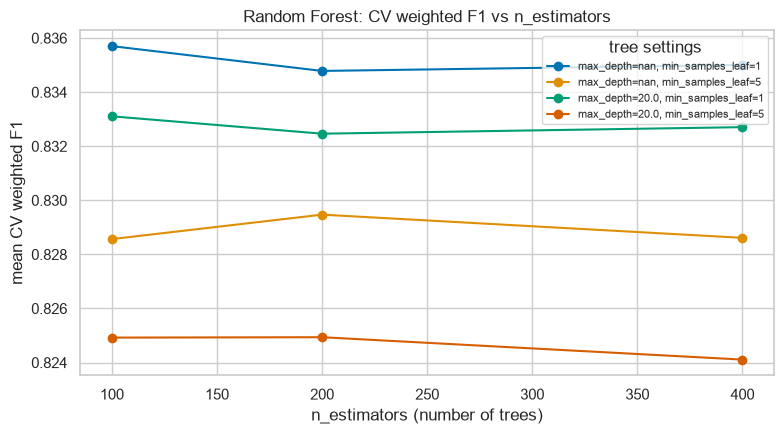

In [6]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for (depth, leaf), grp in rf_cv.groupby(['param_max_depth', 'param_min_samples_leaf'], dropna=False):
    grp = grp.sort_values('param_n_estimators')
    ax.plot(grp['param_n_estimators'], grp['mean_test_score'], marker='o',
            label=f'max_depth={depth}, min_samples_leaf={leaf}')
ax.set_title('Random Forest: CV weighted F1 vs n_estimators')
ax.set_xlabel('n_estimators (number of trees)')
ax.set_ylabel('mean CV weighted F1')
ax.legend(title='tree settings', fontsize=8)
save_fig('rf_n_estimators_curve.png')
plt.show()

**Observation.**
- The curves are flat in `n_estimators`: 100, 200 and 400 trees differ by less than 0.001 in CV weighted F1, so
  ~100 trees already average away most of the variance and more trees only cost time. CV picks 100.
- Tree size matters more. Fully grown trees (`max_depth=None`, `min_samples_leaf=1`) score best on weighted F1
  (0.836) even though they fit the training folds far better (train F1 0.965) — the forest's averaging absorbs that
  overfitting. Larger leaves (`min_samples_leaf=5`) close the train/CV gap (0.842 vs 0.829) but lose ~0.006 F1.

In [7]:
rf = rf_search.best_estimator_
models['Random Forest'] = rf
results['Random Forest (tuned)'] = score(rf, X_test, y_test)
display(pd.DataFrame({k: v for k, v in results.items() if k.startswith('Random Forest')}).T.round(4))

,accuracy,precision_weighted,recall_weighted,f1_weighted,f1_macro,balanced_accuracy,roc_auc
Random Forest (base),0.822,0.8593,0.822,0.831,0.7888,0.8339,0.9170
Random Forest (tuned),0.833,0.8406,0.833,0.836,0.7844,0.7959,0.8968


**Observation.** Tuning improves the metric it optimised: accuracy +0.011 and weighted F1 +0.005. It is not a free
win: ROC-AUC drops from 0.917 to 0.897 and balanced accuracy from 0.834 to 0.796. Fully grown trees have pure leaves,
so their averaged probabilities are coarser and rank people less well, and they recall fewer `>50K` people. If the
goal were ranking / catching the minority class, the base forest (`min_samples_leaf=5`) would be the better choice.

### 2.2 Feature importance

Impurity-based importance (mean decrease in Gini) of the tuned forest. One-hot columns are summed back to their
original feature so a 41-level `native-country` is not split into 41 tiny bars.

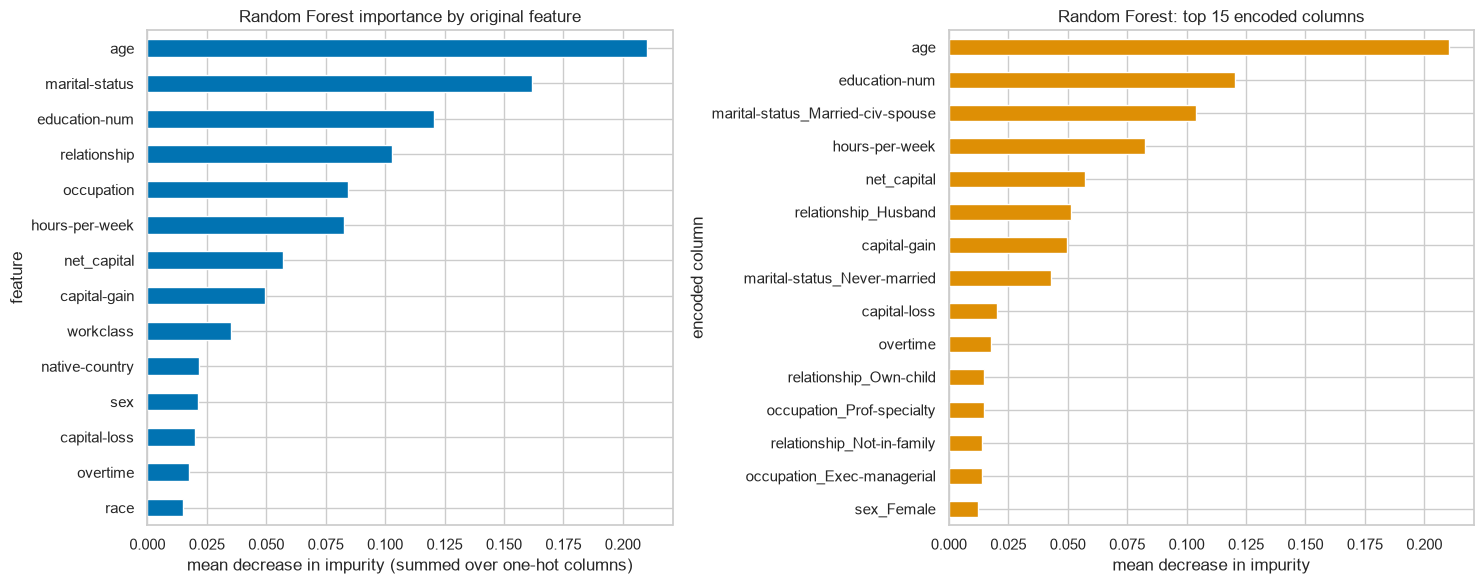

{'age': 0.21, 'marital-status': 0.162, 'education-num': 0.121, 'relationship': 0.103, 'occupation': 0.084, 'hours-per-week': 0.083, 'net_capital': 0.057, 'capital-gain': 0.05, 'workclass': 0.035, 'native-country': 0.022, 'sex': 0.021, 'capital-loss': 0.02, 'overtime': 0.018, 'race': 0.015}


In [8]:
imp = pd.Series(rf.feature_importances_, index=X_train.columns)
cat_prefixes = ['workclass', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']
def base_feature(col):
    for p in cat_prefixes:
        if col.startswith(p + '_'):
            return p
    return col
grouped = imp.groupby(base_feature).sum().sort_values()

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
grouped.plot.barh(ax=axes[0], color=sns.color_palette('colorblind')[0])
axes[0].set_title('Random Forest importance by original feature')
axes[0].set_xlabel('mean decrease in impurity (summed over one-hot columns)')
axes[0].set_ylabel('feature')
imp.sort_values().tail(15).plot.barh(ax=axes[1], color=sns.color_palette('colorblind')[1])
axes[1].set_title('Random Forest: top 15 encoded columns')
axes[1].set_xlabel('mean decrease in impurity')
axes[1].set_ylabel('encoded column')
save_fig('rf_feature_importance.png')
plt.show()
print(grouped.sort_values(ascending=False).round(3).to_dict())

**Observation.** `age` (0.21), `marital-status` (0.16), `education-num` (0.12) and `relationship` (0.10) carry
most of the splits — the same signals the Review 1 EDA found (married people and those with 13+ years of education
earn `>50K` far more often). The engineered `net_capital` (0.057) ranks above the raw `capital-gain` (0.050), so the
Review 1 feature is used. `native-country` (0.022) and `race` (0.015) contribute little, matching their heavy
concentration in one value.
Impurity importance favours features with many distinct values (age, hours), so it shows what the forest *uses*,
not a causal effect.

## 3. AdaBoost

Boosting builds an additive model of weak learners **sequentially**: after each round, misclassified rows get a
larger weight so the next learner focuses on them. The default weak learner is a depth-1 tree (a *stump*).
`learning_rate` shrinks each learner's contribution, so it trades off against `n_estimators` — a smaller rate needs
more rounds.

AdaBoost has no `class_weight` option; balanced **sample weights** are passed to `fit` instead so it sees the same
re-weighting as the other models.

In [9]:
from sklearn.ensemble import AdaBoostClassifier
from sklearn.utils.class_weight import compute_sample_weight

sw_train = compute_sample_weight('balanced', y_train)

ada_base = AdaBoostClassifier(n_estimators=50, learning_rate=1.0, random_state=RANDOM_STATE)
ada_base.fit(X_train, y_train, sample_weight=sw_train)
results['AdaBoost (base)'] = score(ada_base, X_test, y_test)
pd.Series(results['AdaBoost (base)']).round(4)

accuracy              0.8080
precision_weighted    0.8466
recall_weighted       0.8080
f1_weighted           0.8177
f1_macro              0.7723
balanced_accuracy     0.8158
roc_auc               0.9025
dtype: float64

### 3.1 Tuning `n_estimators` and `learning_rate`

Both parameters from the guideline are tuned together because they interact. The balanced sample weights are
routed through `GridSearchCV.fit`, so each CV fold uses the weights of its own training rows.

In [10]:
ada_grid = {
    'n_estimators': [100, 300, 500],
    'learning_rate': [0.1, 0.5, 1.0],
}
ada_search = GridSearchCV(AdaBoostClassifier(random_state=RANDOM_STATE), ada_grid, scoring='f1_weighted',
                          cv=CV, n_jobs=-1, return_train_score=True)
ada_search.fit(X_train, y_train, sample_weight=sw_train)
print('best params:', ada_search.best_params_)
print('best CV weighted F1: %.4f' % ada_search.best_score_)

ada_cv = (pd.DataFrame(ada_search.cv_results_)
          [['param_n_estimators', 'param_learning_rate', 'mean_train_score', 'mean_test_score', 'std_test_score']]
          .sort_values('mean_test_score', ascending=False).reset_index(drop=True))
display(ada_cv.round(4))

best params: {'learning_rate': 1.0, 'n_estimators': 500}
best CV weighted F1: 0.8275


,param_n_estimators,param_learning_rate,mean_train_score,mean_test_score,std_test_score
0,500,1.0,0.8282,0.8275,0.0040
1,500,0.5,0.8275,0.8270,0.0014
2,300,1.0,0.8269,0.8264,0.0034
3,300,0.5,0.8262,0.8250,0.0019
4,100,1.0,0.8236,0.8233,0.0039
5,100,0.5,0.8194,0.8190,0.0011
6,500,0.1,0.8164,0.8155,0.0020
7,300,0.1,0.8087,0.8073,0.0029
8,100,0.1,0.7878,0.7876,0.0027


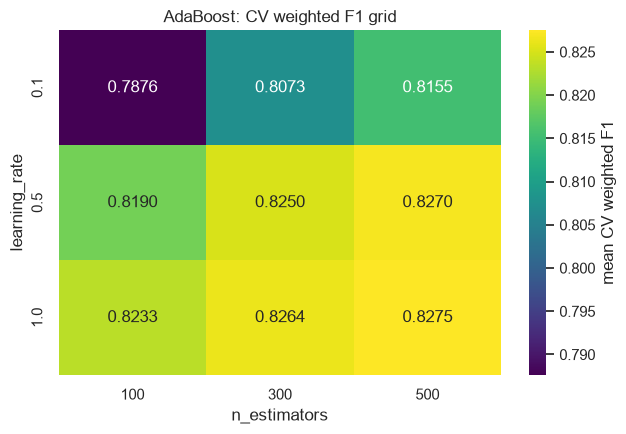

In [11]:
heat = ada_cv.pivot(index='param_learning_rate', columns='param_n_estimators', values='mean_test_score')
plt.figure(figsize=(6.5, 4.5))
sns.heatmap(heat, annot=True, fmt='.4f', cmap='viridis', cbar_kws={'label': 'mean CV weighted F1'})
plt.title('AdaBoost: CV weighted F1 grid')
plt.xlabel('n_estimators')
plt.ylabel('learning_rate')
save_fig('adaboost_grid_heatmap.png')
plt.show()

**Observation.**
- The trade-off is visible: with `learning_rate=0.1` the score is still climbing at 500 rounds (0.788 -> 0.816), while
  `learning_rate=1.0` is already at 0.823 after 100 rounds. Best: `learning_rate=1.0`, `n_estimators=500` (CV 0.8275).
- That best value sits on the edge of the grid, but 300 -> 500 rounds only adds 0.001, so a larger grid would gain little.
- Train and CV scores differ by less than 0.002 for every setting: unlike the forest, boosted stumps are not
  overfitting here. Their limit is bias, since each stump is a single split.

In [12]:
ada = ada_search.best_estimator_
models['AdaBoost'] = ada
results['AdaBoost (tuned)'] = score(ada, X_test, y_test)
display(pd.DataFrame({k: v for k, v in results.items() if k.startswith('AdaBoost')}).T.round(4))

,accuracy,precision_weighted,recall_weighted,f1_weighted,f1_macro,balanced_accuracy,roc_auc
AdaBoost (base),0.8080,0.8466,0.8080,0.8177,0.7723,0.8158,0.9025
AdaBoost (tuned),0.8138,0.8506,0.8138,0.8231,0.7786,0.8215,0.9097


### 3.2 Staged test score

`staged_predict` gives the prediction after each boosting round, showing how weighted F1 on the test set grows as
stumps are added (diagnostic only — the number of rounds was already chosen by CV).

/opt/homebrew/Cellar/jupyterlab/4.6.2/libexec/lib/python3.14/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but AdaBoostClassifier was fitted with feature names
  warnings.warn(


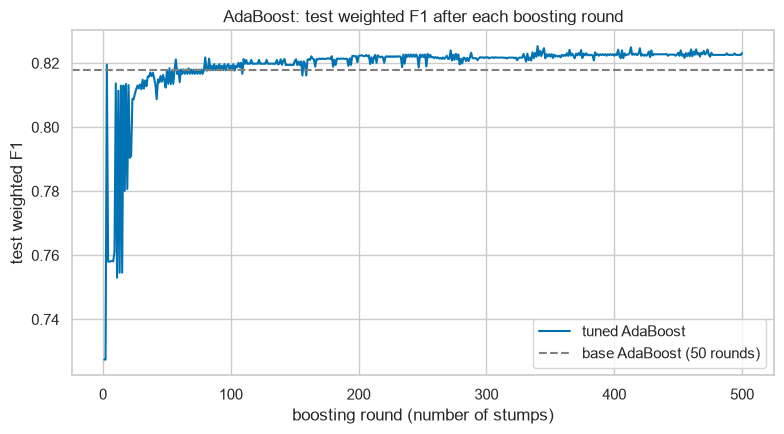

In [13]:
staged_f1 = [f1_score(y_test, p, average='weighted') for p in ada.staged_predict(X_test)]
plt.figure(figsize=(8, 4.5))
plt.plot(range(1, len(staged_f1) + 1), staged_f1, label='tuned AdaBoost')
plt.axhline(results['AdaBoost (base)']['f1_weighted'], color='grey', ls='--', label='base AdaBoost (50 rounds)')
plt.title('AdaBoost: test weighted F1 after each boosting round')
plt.xlabel('boosting round (number of stumps)')
plt.ylabel('test weighted F1')
plt.legend()
save_fig('adaboost_staged_f1.png')
plt.show()

**Observation.** One stump alone gives weighted F1 0.727; ten rounds already reach 0.814. From 50 rounds (0.818) to 500
(0.823) the curve only creeps up, so most of the tuning gain comes from the extra rounds, at roughly 10x the training time.